<a href="https://colab.research.google.com/github/Abjith006/CAT-2-DEEP-LEARNING/blob/main/STOCK_IPYNP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Upload your Dataset
Run the cell below to trigger an upload prompt and select files from your local machine.

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jainilcoder/netflix-stock-price-prediction")

print("Path to dataset files:", path)

100%|██████████| 20.9k/20.9k [00:00<00:00, 10.4MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/jainilcoder/netflix-stock-price-prediction/versions/1


In [ ]:
import os
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# List files in the downloaded directory to find the CSV
files_in_dir = os.listdir(path)
print("Files in dataset directory:", files_in_dir)

# Identify the CSV file
csv_files = [f for f in files_in_dir if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print("\nInitial Data Info:")
    print(df.info())
    display(df.head())
else:
    print("No CSV file found in the dataset directory.")

In [ ]:
# Clean and preprocess the data
# 1. Convert Date column to datetime format
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])

# 2. Check and handle missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)

# Drop rows with null values if any exist
df = df.dropna()

# Sort by Date
df = df.sort_values(by='Date').reset_index(drop=True)
display(df.head())

In [ ]:
# Normalize the stock price columns and Volume using MinMaxScaler
scaler = MinMaxScaler()

# Identify numeric columns for normalization (excluding Date)
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
print("Columns to be normalized:", numeric_cols)

# Apply Normalization
df_normalized = df.copy()
df_normalized[numeric_cols] = scaler.fit_transform(df[numeric_cols])

print("\nNormalized DataFrame:")
display(df_normalized.head())

### Generate Input-Output Sequences (Sliding Window)
To train sequential models like LSTMs or GRUs, we need to transform our time-series data into overlapping windows of a fixed size. We will use the normalized `Close` price to create these sequences.

In [ ]:
import numpy as np

def create_sequences(data, window_size):
    X = []
    y = []
    for i in range(len(data) - window_size):
        X.append(data[i:(i + window_size)])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

# Let's target the 'Close' price for forecasting
target_data = df_normalized['Close'].values

# Define a suitable window size (e.g., 60 historical days to predict the 61st day)
window_size = 60

X, y = create_sequences(target_data, window_size)

print(f"Total data points: {len(target_data)}")
print(f"Input shape (X): {X.shape} -> (samples, window_size)")
print(f"Output shape (y): {y.shape} -> (samples,)")

In [ ]:
# Show an example of the first generated sequence and its corresponding target
print(f"First input sequence (first 5 values out of {window_size}):\n", X[0][:5])
print(f"\nFirst target value (the {window_size + 1}th day's value):\n", y[0])

### Model Selection & Training (LSTM)
We will use a Sequential LSTM architecture with TensorFlow/Keras to learn and predict the next day's normalized closing price.

In [6]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# 1. Load data
files_in_dir = os.listdir(path)
csv_files = [f for f in files_in_dir if f.endswith('.csv')]
csv_path = os.path.join(path, csv_files[0])
df = pd.read_csv(csv_path)

# 2. Clean and preprocess
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna().sort_values(by='Date').reset_index(drop=True)

# 3. Normalize
scaler = MinMaxScaler()
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
df_normalized = df.copy()
df_normalized[numeric_cols] = scaler.fit_transform(df[numeric_cols])

# 4. Generate sequences
def create_sequences(data, window_size):
    X_seq, y_seq = [], []
    for i in range(len(data) - window_size):
        X_seq.append(data[i:(i + window_size)])
        y_seq.append(data[i + window_size])
    return np.array(X_seq), np.array(y_seq)

window_size = 60
target_data = df_normalized['Close'].values
X, y = create_sequences(target_data, window_size)

# 5. Reshape and Split
X_reshaped = np.reshape(X, (X.shape[0], X.shape[1], 1))
split_index = int(len(X_reshaped) * 0.8)
X_train, X_val = X_reshaped[:split_index], X_reshaped[split_index:]
y_train, y_val = y[:split_index], y[split_index:]

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")

Training set shape: (759, 60, 1)
Validation set shape: (190, 60, 1)


In [7]:
# 6. Define and Compile the LSTM Model
model = Sequential([
    LSTM(units=50, return_sequences=True, input_shape=(window_size, 1)),
    Dropout(0.2),
    LSTM(units=50, return_sequences=False),
    Dropout(0.2),
    Dense(units=25),
    Dense(units=1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# 7. Train the Model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    verbose=1
)

Epoch 1/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - loss: 0.0292 - val_loss: 0.0184
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0046 - val_loss: 0.0059
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0037 - val_loss: 0.0062
Epoch 4/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0033 - val_loss: 0.0054
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0034 - val_loss: 0.0060
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0031 - val_loss: 0.0052
Epoch 7/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - loss: 0.0033 - val_loss: 0.0056
Epoch 8/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - loss: 0.0029 - val_loss: 0.0058
Epoch 9/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0028 - val_loss: 0.0052
Epoch 10/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0029 - val_loss: 0.0042
Epoch 11/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0026 - val_loss: 0.0047
Epoch 12/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0

### Model Evaluation & Visualization
We will predict the stock prices on our validation dataset, inverse-transform the normalized values back to original dollars, and plot the comparative curves.

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
import math

# 1. Make predictions on validation data
predictions = model.predict(X_val)

# 2. To inverse-transform, we need a 2D array matching the scaler's original fit
# We will construct dummy arrays to invert the normalization specifically for 'Close' prices
dummy_predictions = np.zeros((len(predictions), len(numeric_cols)))
dummy_actuals = np.zeros((len(y_val), len(numeric_cols)))

# Locate index of 'Close' inside numeric_cols
close_idx = numeric_cols.index('Close')
dummy_predictions[:, close_idx] = predictions.flatten()
dummy_actuals[:, close_idx] = y_val

# Inverse transform
predictions_unscaled = scaler.inverse_transform(dummy_predictions)[:, close_idx]
actuals_unscaled = scaler.inverse_transform(dummy_actuals)[:, close_idx]

# 3. Calculate RMSE
rmse = math.sqrt(mean_squared_error(actuals_unscaled, predictions_unscaled))
print(f"Validation Root Mean Squared Error (RMSE): ${rmse:.2f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step
Validation Root Mean Squared Error (RMSE): $27.59


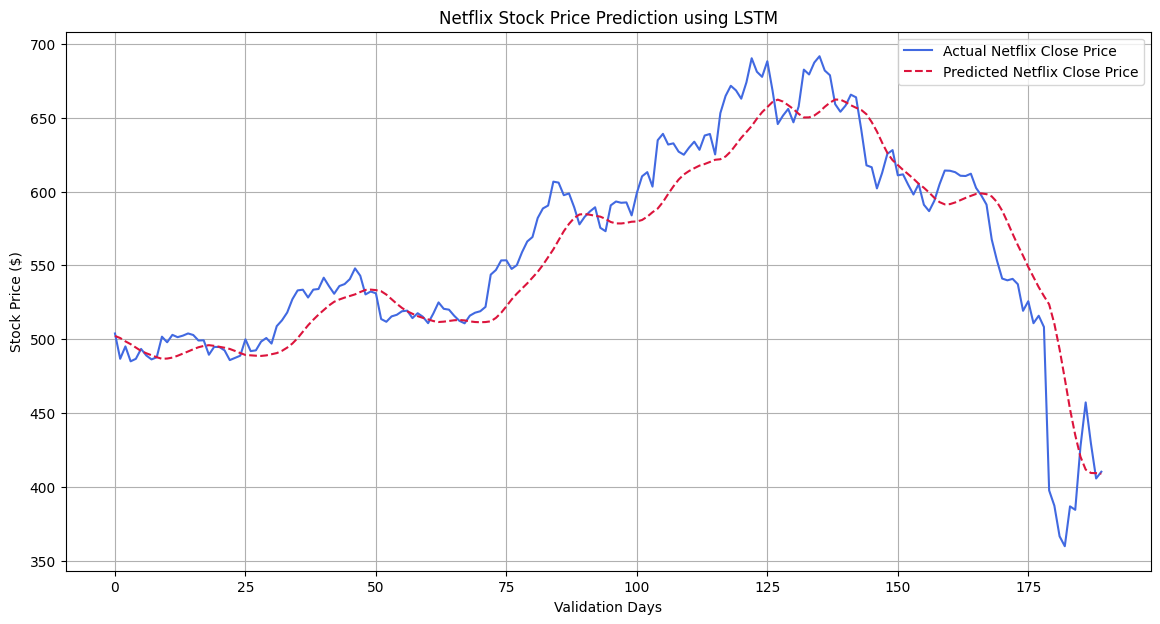

In [10]:
# 4. Plot Predicted vs Actual prices
plt.figure(figsize=(14, 7))
plt.plot(actuals_unscaled, label='Actual Netflix Close Price', color='royalblue')
plt.plot(predictions_unscaled, label='Predicted Netflix Close Price', color='crimson', linestyle='--')
plt.title('Netflix Stock Price Prediction using LSTM')
plt.xlabel('Validation Days')
plt.ylabel('Stock Price ($)')
plt.legend()
plt.grid(True)
plt.show()

### Prediction on Unseen Dates
To predict unseen future dates beyond our dataset, we can use the most recent 60-day window from the data to forecast the next business day's price.

In [11]:
# 1. Extract the last 60 days of normalized Close prices from the dataset
last_60_days = df_normalized['Close'].values[-window_size:]
last_60_days_reshaped = np.reshape(last_60_days, (1, window_size, 1))

# 2. Predict the next unseen day's price
predicted_normalized = model.predict(last_60_days_reshaped)

# 3. Denormalize the prediction back to USD
dummy_pred = np.zeros((1, len(numeric_cols)))
dummy_pred[0, close_idx] = predicted_normalized[0, 0]
unseen_prediction_usd = scaler.inverse_transform(dummy_pred)[0, close_idx]

# 4. Determine the next unseen date
last_date = df['Date'].max()
next_date = last_date + pd.offsets.BDay(1)

print(f"Last date in dataset: {last_date.strftime('%Y-%m-%d')} (Actual Close Price: ${df['Close'].iloc[-1]:.2f})")
print(f"Predicted Close Price for unseen business day ({next_date.strftime('%Y-%m-%d')}): ${unseen_prediction_usd:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Last date in dataset: 2022-02-04 (Actual Close Price: $410.17)
Predicted Close Price for unseen business day (2022-02-07): $408.54
